In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

In [2]:
import pickle

import pandas as pd
from benchmark_func import params_search, print_summary, run_benchmark, show_graph

from algorithms.baseline import UserBasedCF
from algorithms.implicit_als import ImplicitALS
from utils.data_load import load_dataset, make_subset, save_df, split_train_test_by_time
from utils.data_stats import dataframe_stats

c:\Users\shsas\miniconda3\envs\recsys-benchmark\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
pd.set_option("display.max_columns", 25)

In [ ]:
DATA_PATH = "../data/raw/ratings.csv"

DATA_TRAIN_1M_PATH = "../data/processed/train_1M.csv"
DATA_VAL_1M_PATH = "../data/processed/val_1M.csv"
DATA_TEST_1M_PATH = "../data/processed/test_1M.csv"

DATA_TRAIN_10M_PATH = "../data/processed/train_10M.csv"
DATA_VAL_10M_PATH = "../data/processed/val_10M.csv"
DATA_TEST_10M_PATH = "../data/processed/test_10M.csv"

DATA_TRAIN_32M_PATH = "../data/processed/train_32M.csv"
DATA_VAL_32M_PATH = "../data/processed/val_32M.csv"
DATA_TEST_32M_PATH = "../data/processed/test_32M.csv"

N_RUNS = 3

USERBASED_CF_PARAMS_SEARCH_PATH = "../data/processed/df_UserBasedCF_3.pkl"
IMPLICIT_ALS_PARAMS_SEARCH_PATH = "../data/processed/df_ImplicitALS_3.pkl"

In [5]:
df = load_dataset(path=DATA_PATH)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32000204 entries, 0 to 32000203
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int64  
 1   movieId    int64  
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(3)
memory usage: 976.6 MB


In [6]:
df.head()

,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


In [7]:
try:
    train = load_dataset(DATA_TRAIN_1M_PATH)
    val = load_dataset(DATA_VAL_1M_PATH)
    test = load_dataset(DATA_TEST_1M_PATH)
except FileNotFoundError:
    subset = make_subset(df=df, n_ratings=1_000_000)
    train_val, test = split_train_test_by_time(subset, test_frac=0.2)
    train, val = split_train_test_by_time(train_val, test_frac=0.125)
    save_df(df=train, path=DATA_TRAIN_1M_PATH)
    save_df(df=val, path=DATA_VAL_1M_PATH)
    save_df(df=test, path=DATA_TEST_1M_PATH)

print(train.shape, val.shape, test.shape)

(700135, 4) (99921, 4) (199960, 4)


In [8]:
train.describe()

,userId,movieId,rating,timestamp
count,700135.000000,700135.000000,700135.000000,7.001350e+05
mean,99191.717673,25537.721149,3.579263,1.268655e+09
std,58380.642285,45573.005045,1.051947,2.541866e+08
min,10.000000,1.000000,0.500000,8.253600e+08
25%,48911.000000,1200.000000,3.000000,1.042391e+09
50%,98122.000000,3033.000000,4.000000,1.269987e+09
75%,150569.000000,32587.000000,4.000000,1.493711e+09
max,200935.000000,291803.000000,5.000000,1.696869e+09


In [9]:
val.describe()

,userId,movieId,rating,timestamp
count,99921.000000,99921.000000,99921.000000,9.992100e+04
mean,99189.740345,33998.187668,3.466944,1.288774e+09
std,58376.697991,54428.433186,1.055431,2.562579e+08
min,10.000000,1.000000,0.500000,8.256384e+08
25%,48911.000000,1339.000000,3.000000,1.066187e+09
50%,98100.000000,3996.000000,3.500000,1.306351e+09
75%,150569.000000,54270.000000,4.000000,1.515867e+09
max,200935.000000,288513.000000,5.000000,1.696869e+09


In [10]:
test.describe()

,userId,movieId,rating,timestamp
count,199960.000000,199960.000000,199960.000000,1.999600e+05
mean,99188.357041,41039.464603,3.473062,1.307114e+09
std,58381.433520,64470.101002,1.057868,2.639991e+08
min,10.000000,1.000000,0.500000,8.256384e+08
25%,48911.000000,1419.000000,3.000000,1.078707e+09
50%,98122.000000,4427.500000,3.500000,1.334686e+09
75%,150574.000000,63859.000000,4.000000,1.546718e+09
max,200935.000000,291807.000000,5.000000,1.697158e+09


In [11]:
stats = pd.concat(
    {
        "train_1M": dataframe_stats(df=load_dataset(DATA_TRAIN_1M_PATH)),
        "val_1M":  dataframe_stats(df=load_dataset(DATA_VAL_1M_PATH)),
        "test_1M":  dataframe_stats(df=load_dataset(DATA_TEST_1M_PATH)),
        "train_10M": dataframe_stats(df=load_dataset(DATA_TRAIN_10M_PATH)),
        "val_10M":  dataframe_stats(df=load_dataset(DATA_VAL_10M_PATH)),
        "test_10M":  dataframe_stats(df=load_dataset(DATA_TEST_10M_PATH)),
        "train_32M": dataframe_stats(df=load_dataset(DATA_TRAIN_32M_PATH)),
        "val_32M":  dataframe_stats(df=load_dataset(DATA_VAL_32M_PATH)),
        "test_32M":  dataframe_stats(df=load_dataset(DATA_TEST_32M_PATH)),
    },
    names=["subset_split"],
).reset_index(level="subset_split")

stats

,subset_split,n_users,n_items,n_ratings,density,sparsity,user_ratings_median,user_ratings_p95,user_ratings_max,item_ratings_median,item_ratings_p95,item_ratings_max,frac_users_lt_5,frac_items_lt_5,frac_ratings_ge_3.5,df_memory_mb,rating_mean,rating_std,rating_min,rating_max,rating_median
0,train_1M,6373,20440,700135,0.005375,0.994625,52.0,394.0,3954,3.0,167.00,2854,0.000000,0.599266,0.647119,21.366550,3.579263,1.051947,0.5,5.0,4.0
0,val_1M,6373,12610,99921,0.001243,0.998757,7.0,56.0,565,2.0,37.00,201,0.322925,0.681285,0.610863,3.049473,3.466944,1.055431,0.5,5.0,3.5
0,test_1M,6373,17425,199960,0.001801,0.998199,15.0,112.4,1130,2.0,56.00,294,0.063706,0.641836,0.614738,6.102421,3.473062,1.057868,0.5,5.0,3.5
0,train_10M,62946,46788,7001294,0.002377,0.997623,51.0,398.0,6311,3.0,541.65,28635,0.000000,0.569740,0.642551,213.662663,3.573083,1.051692,0.5,5.0,4.0
0,val_10M,62946,30999,999099,0.000512,0.999488,7.0,57.0,902,2.0,168.00,1811,0.333143,0.616697,0.611499,30.490208,3.475512,1.049316,0.5,5.0,3.5
0,test_10M,62946,44435,1999637,0.000715,0.999285,14.0,114.0,1803,2.0,229.00,3060,0.066311,0.614583,0.616517,61.024204,3.481425,1.047734,0.5,5.0,3.5
0,train_32M,200948,65583,22403910,0.001700,0.998300,51.0,400.0,23333,4.0,1020.00,91080,0.000000,0.507342,0.640847,683.713200,3.569123,1.059275,0.5,5.0,4.0
0,val_32M,200948,47984,3197329,0.000332,0.999668,7.0,57.0,3333,3.0,311.00,5829,0.331190,0.602013,0.609419,97.574863,3.471042,1.055535,0.5,5.0,3.5
0,test_32M,200948,68517,6398965,0.000465,0.999535,15.0,114.0,6666,3.0,408.00,9775,0.065619,0.587227,0.612965,195.281040,3.474468,1.055137,0.5,5.0,3.5


In [12]:
def model_factory():
    return UserBasedCF(top_k=20)

results = run_benchmark(model_factory, train, val, n_runs=N_RUNS)

print_summary(results)

[timer] Обучение UserBasedCF(top_k=20): 2.680 сек.
[memory_usage] Обучение UserBasedCF(top_k=20): 1164.598 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=20): 5.550 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=20): 498.594 MB
[timer] Обучение UserBasedCF(top_k=20): 2.410 сек.
[memory_usage] Обучение UserBasedCF(top_k=20): 1151.160 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=20): 5.528 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=20): 497.215 MB
[timer] Обучение UserBasedCF(top_k=20): 2.486 сек.
[memory_usage] Обучение UserBasedCF(top_k=20): 1150.242 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=20): 5.637 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=20): 497.125 MB
Модель UserBasedCF
Среднее train_time 2.5252325534820557
Среднее pred_time 5.571695566177368
Средний прирост RSS процесса при обучении: 1155.333 MB
Средний пиковый RSS процесса при обучении: 2371.260 MB
Средний прирост RSS процесса при прогнозе: 497.645 MB
Средний пиковый RSS 

Подбор гиперпараметров для базовой модели `UserBasedCF`

In [13]:
df_UserBasedCF = params_search(
    model_factory=lambda **kw: UserBasedCF(**kw),
    train=train,
    test=val,
    params={"top_k": [5, 10, 15, 20, 30, 50, 100]},
    n_runs=N_RUNS,
)

with open(USERBASED_CF_PARAMS_SEARCH_PATH, "wb") as f:
    pickle.dump(df_UserBasedCF, f)

[timer] Обучение UserBasedCF(top_k=5): 2.527 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1151.461 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.786 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 497.113 MB
[timer] Обучение UserBasedCF(top_k=5): 2.504 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1149.527 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.775 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 497.113 MB
[timer] Обучение UserBasedCF(top_k=5): 2.526 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1150.199 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.778 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 497.164 MB
[timer] Обучение UserBasedCF(top_k=10): 2.577 сек.
[memory_usage] Обучение UserBasedCF(top_k=10): 1151.000 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=10): 3.768 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=10): 497.031 MB
[timer] Обучение UserBasedCF(top_k=10): 2.515 се

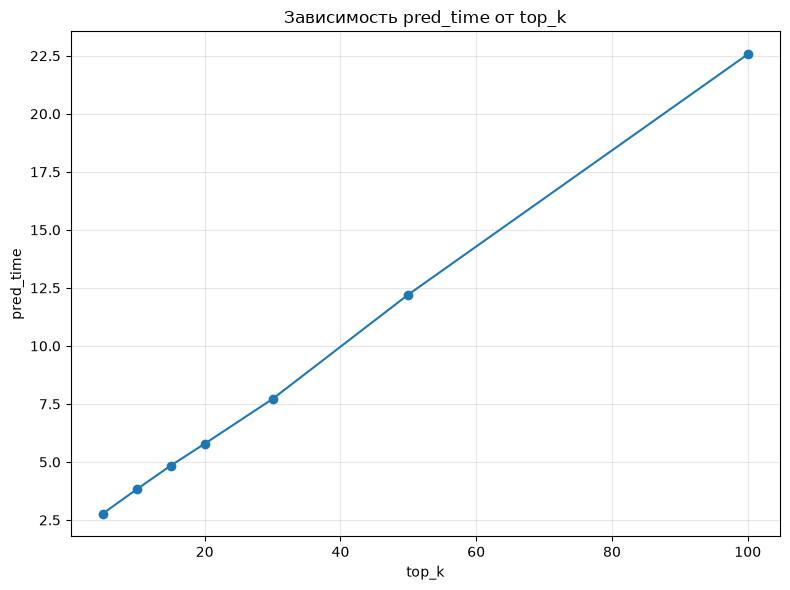

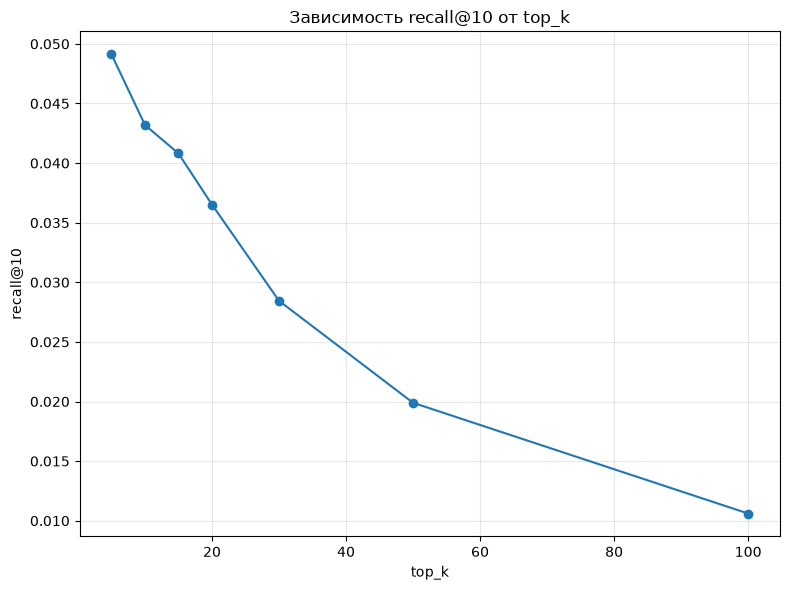

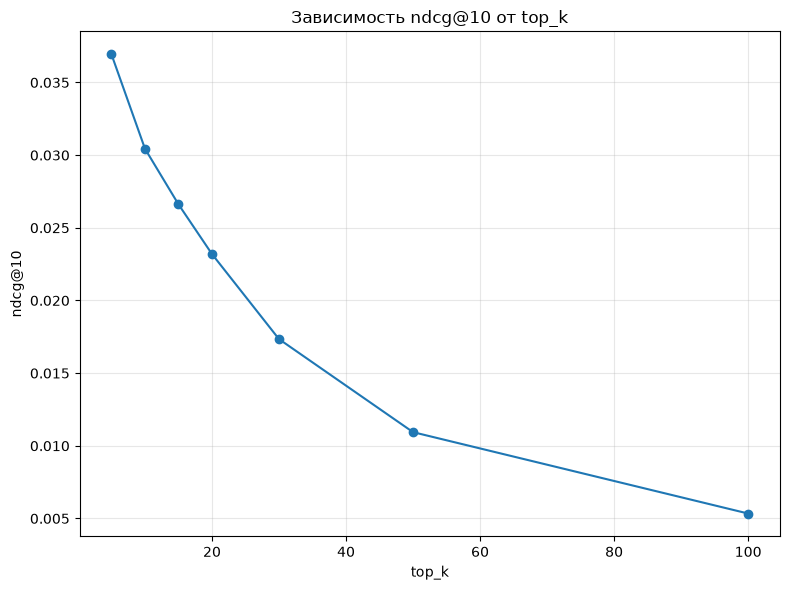

In [14]:
with open(USERBASED_CF_PARAMS_SEARCH_PATH, "rb") as f:
    df_UserBasedCF = pickle.load(f)

show_graph(
    results_df=df_UserBasedCF,
    params=["top_k"],
    metrics=["pred_time", "recall@10", "ndcg@10"],
    save_dir="graphs/UserBasedCF",
)

In [25]:
with open(USERBASED_CF_PARAMS_SEARCH_PATH, "rb") as f:
    df_UserBasedCF = pickle.load(f)

df_UserBasedCF.to_csv("../data/processed/df_UserBasedCF.csv", index=False)

df_UserBasedCF

,top_k,train_time,pred_time,train_mem_delta,train_mem_peak,train_mem_start,pred_mem_delta,pred_mem_peak,pred_mem_start,recall@10,ndcg@10
0,5,2.518868,2.779582,1150.395833,2373.765625,1223.369792,497.130208,2374.013021,1876.882812,0.049126,0.036939
1,10,2.513874,3.824763,1150.246094,2374.579427,1224.333333,497.104167,2374.786458,1877.682292,0.043198,0.030443
2,15,2.419692,4.844039,1150.208333,2375.345052,1225.136719,497.144531,2375.563802,1878.419271,0.040809,0.026616
3,20,2.528724,5.786590,1150.067708,2375.893229,1225.825521,497.048177,2376.053385,1879.005208,0.036518,0.023194
4,30,2.528040,7.715808,1149.734375,2375.708333,1225.973958,496.998698,2376.019531,1879.020833,0.028448,0.017341
5,50,2.458691,12.213709,1149.121094,2375.984375,1226.863281,497.039062,2376.248698,1879.209635,0.019891,0.010939
6,100,2.445573,22.564231,1149.904948,2376.295573,1226.390625,497.096354,2376.606771,1879.510417,0.010602,0.005340


In [16]:
def model_factory():
    return UserBasedCF(top_k=5)

train_val = pd.concat([train, val], ignore_index=True)

results = run_benchmark(model_factory, train_val, test, n_runs=N_RUNS)

print_summary(results)

[timer] Обучение UserBasedCF(top_k=5): 2.659 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1261.965 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.817 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 551.773 MB
[timer] Обучение UserBasedCF(top_k=5): 2.643 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1261.008 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 2.874 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 551.801 MB
[timer] Обучение UserBasedCF(top_k=5): 2.641 сек.
[memory_usage] Обучение UserBasedCF(top_k=5): 1260.785 MB
[timer] Выдача рекомендаций UserBasedCF(top_k=5): 3.019 сек.
[memory_usage] Выдача рекомендаций UserBasedCF(top_k=5): 552.051 MB
Модель UserBasedCF
Среднее train_time 2.647627512613932
Среднее pred_time 2.903406302134196
Средний прирост RSS процесса при обучении: 1261.253 MB
Средний пиковый RSS процесса при обучении: 2518.900 MB
Средний прирост RSS процесса при прогнозе: 551.875 MB
Средний пиковый RSS процесса при 

Таким образом, лучший `top_k=5`:

- при `top_k=5` - самые похожие пользователи, у которых много общих фильмов;
- при `top_k=100` - все, у кого есть хоть 1 общий, включая почти случайных;
- меньше - лучше, потому что сигнал чище.

memory-based CF деградирует при добавлении соседей, потому что нет достаточного числа действительно похожих пользователей.

In [17]:
def model_factory():
    return ImplicitALS(factors=64, iterations=20, regularization=0.05, alpha=40.0)

results = run_benchmark(model_factory, train, val, n_runs=N_RUNS)

print_summary(results)

c:\Users\shsas\miniconda3\envs\recsys-benchmark\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 16 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


[timer] Обучение implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 0.817 сек.
[memory_usage] Обучение implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 63.133 MB
[timer] Выдача рекомендаций implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 1.834 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 0.121 MB
[timer] Обучение implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 0.768 сек.
[memory_usage] Обучение implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 63.672 MB
[timer] Выдача рекомендаций implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 1.820 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 0.023 MB
[timer] Обучение implicit ALS(factors=64, iterations=20, regularization=0.05, alpha=40.0): 0.762 сек.
[memory_usage] О

Чтобы проверить влияние размерности скрытого пространства на смещение в сторону популярных объектов, была посчитана средняя популярность рекомендованных фильмов (среднее число оценок фильма в train) при фиксированных `iterations=30`, `regularization=0.5` и `alpha=10`

In [27]:
item_pop = train["movieId"].value_counts().to_dict()
val_users = val["userId"].unique().tolist()

for f in [16, 32, 64, 128, 256]:
    model = ImplicitALS(factors=f, iterations=30, regularization=0.5, alpha=10.0)
    model.fit(train)
    recs = model.recommend(val_users, n=10)
    
    all_rec_items = [item for items in recs.values() for item in items]
    mean_pop = sum(item_pop.get(i, 0) for i in all_rec_items) / len(all_rec_items)
    print(f"factors={f}: средняя популярность в топ-10 = {mean_pop:.1f} оценок")

factors=16: средняя популярность в топ-10 = 1092.8 оценок
factors=32: средняя популярность в топ-10 = 960.0 оценок
factors=64: средняя популярность в топ-10 = 935.9 оценок
factors=128: средняя популярность в топ-10 = 975.7 оценок
factors=256: средняя популярность в топ-10 = 779.2 оценок


Таким образом, с увеличением factors смещение в сторону популярных фильмов нельзя считать основной причиной роста NDCG@10

In [19]:
df_ImplicitALS = params_search(
    model_factory=lambda **kw: ImplicitALS(**kw),
    train=train,
    test=val,
    params={
        "factors": [16, 32, 64, 128],
        "iterations": [10, 20, 30, 40],
        "regularization": [0.01, 0.05, 0.1, 0.2, 0.5],
        "alpha": [10.0, 20.0, 40.0, 80.0],
    },
    n_runs=N_RUNS,
)

with open(IMPLICIT_ALS_PARAMS_SEARCH_PATH, "wb") as f:
    pickle.dump(df_ImplicitALS, f)

[timer] Обучение implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.372 сек.
[memory_usage] Обучение implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 57.570 MB
[timer] Выдача рекомендаций implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.986 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 1.027 MB
[timer] Обучение implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.369 сек.
[memory_usage] Обучение implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 55.930 MB
[timer] Выдача рекомендаций implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.992 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.652 MB
[timer] Обучение implicit ALS(factors=16, iterations=10, regularization=0.01, alpha=10.0): 0.370 сек.
[memory_usage] О

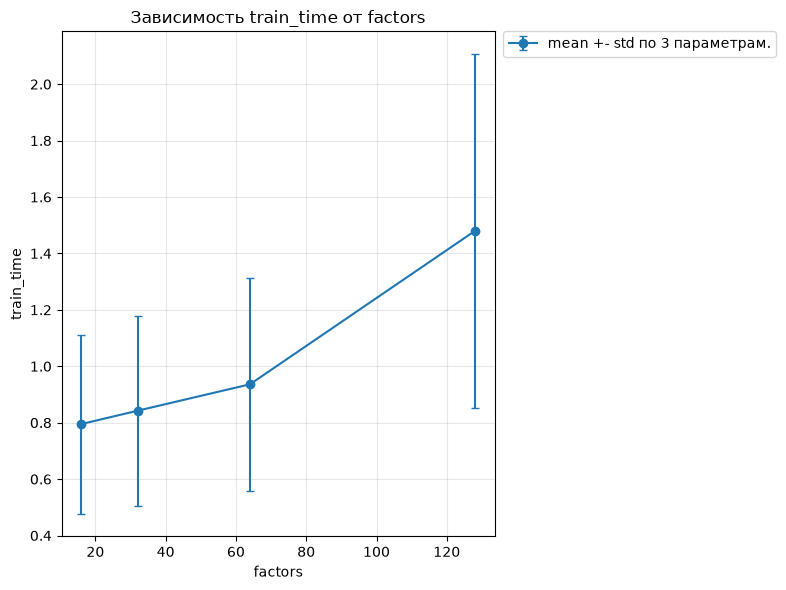

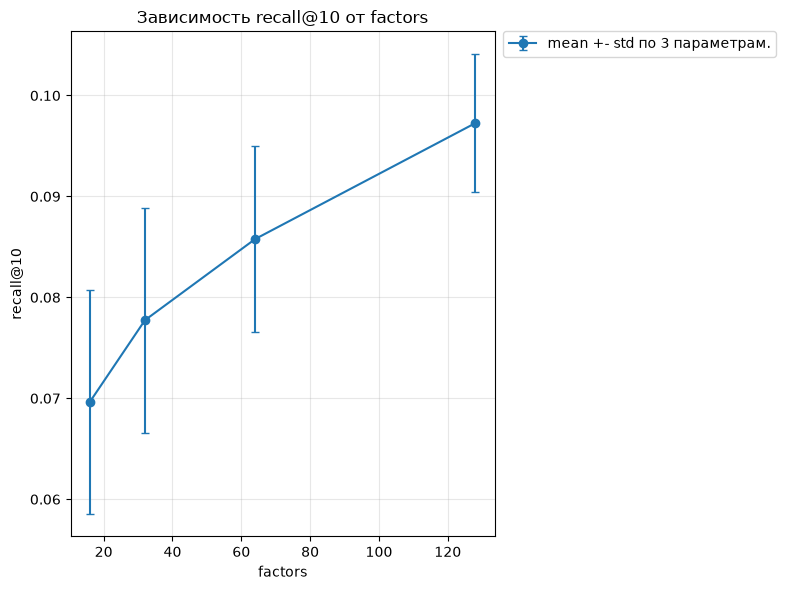

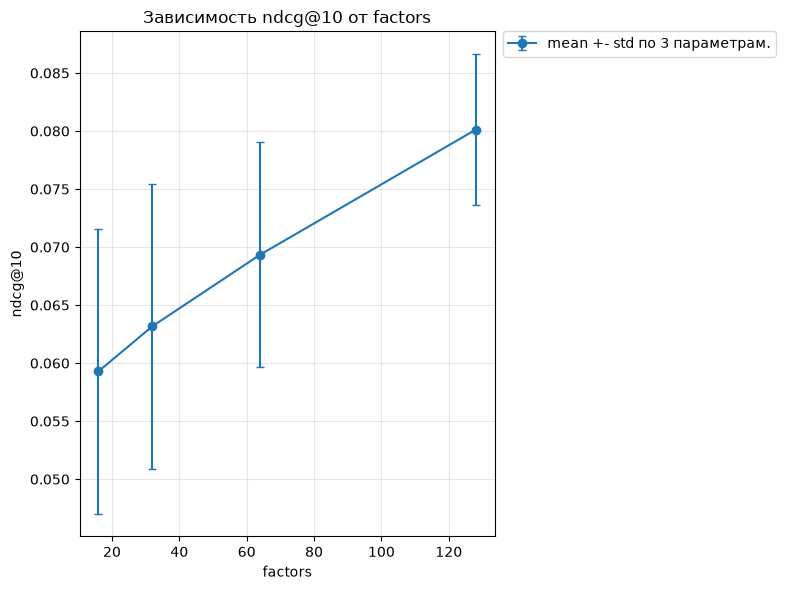

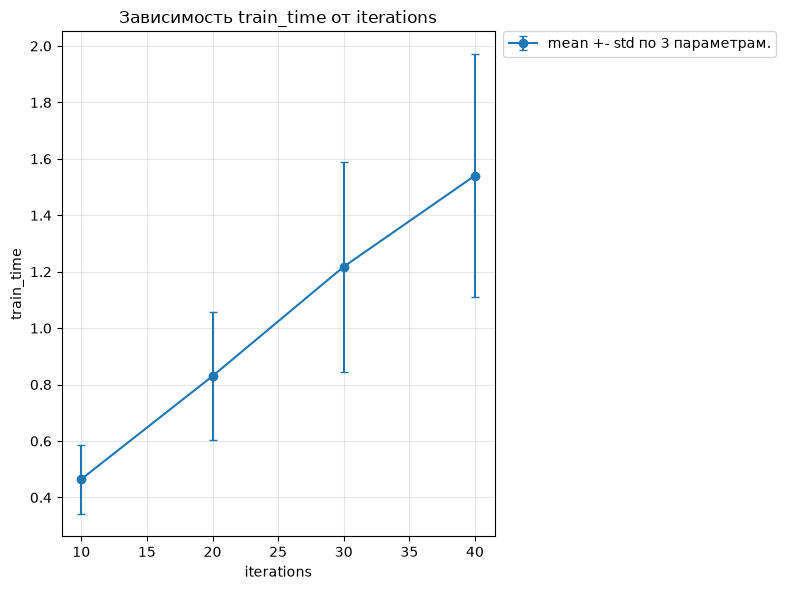

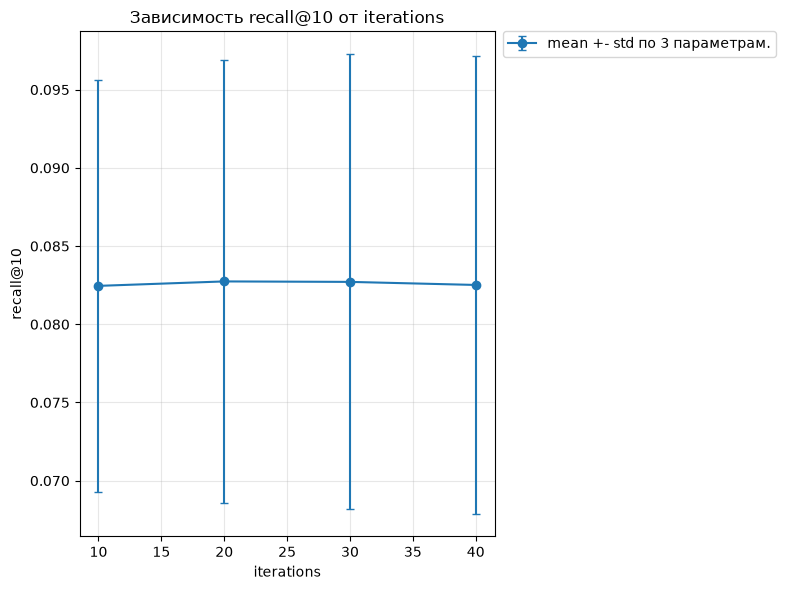

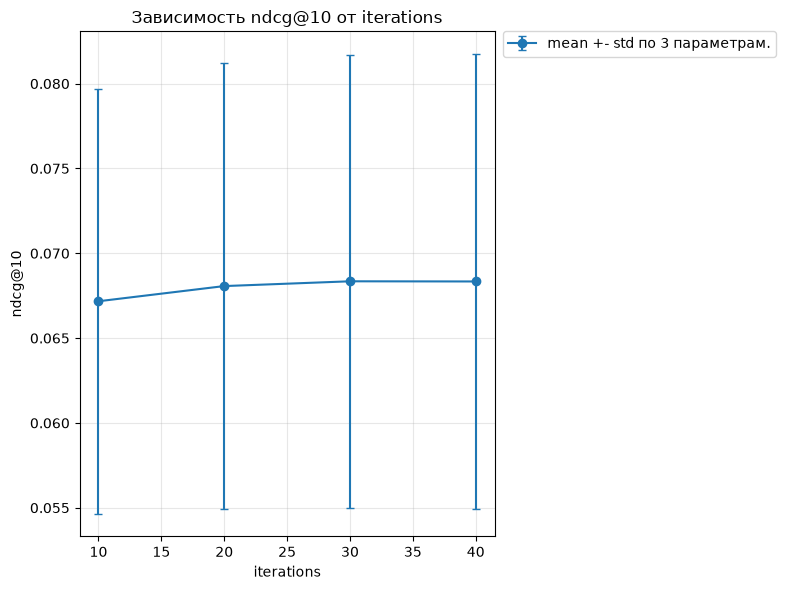

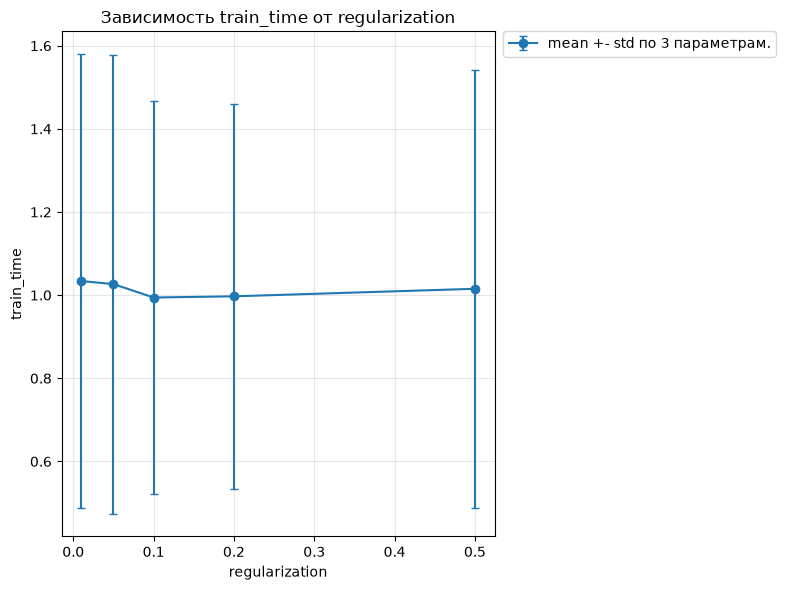

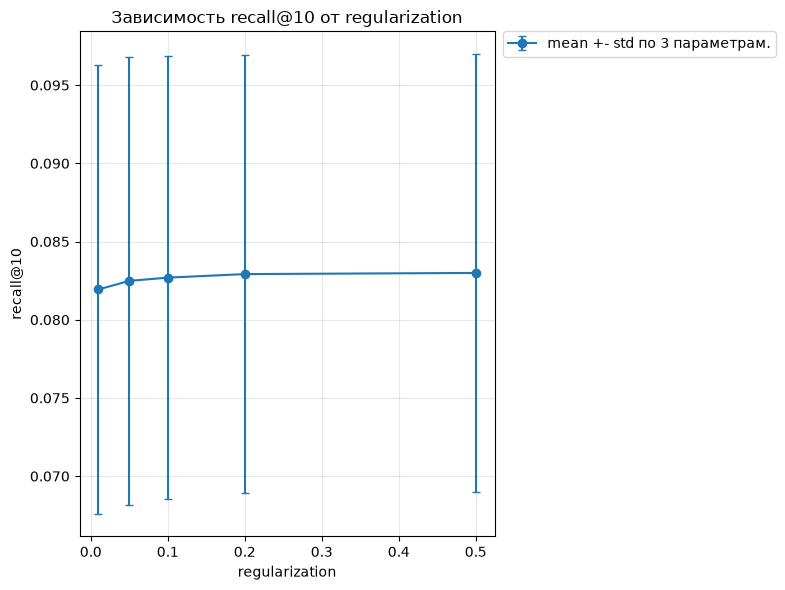

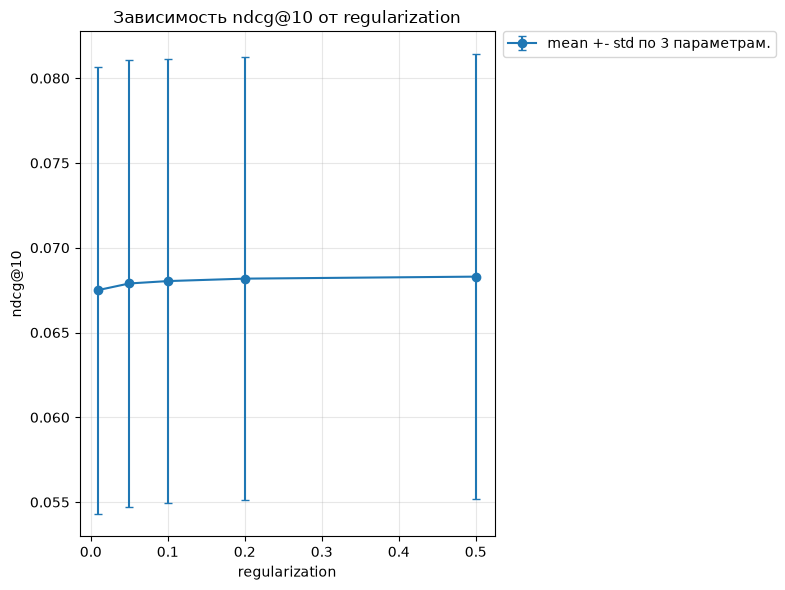

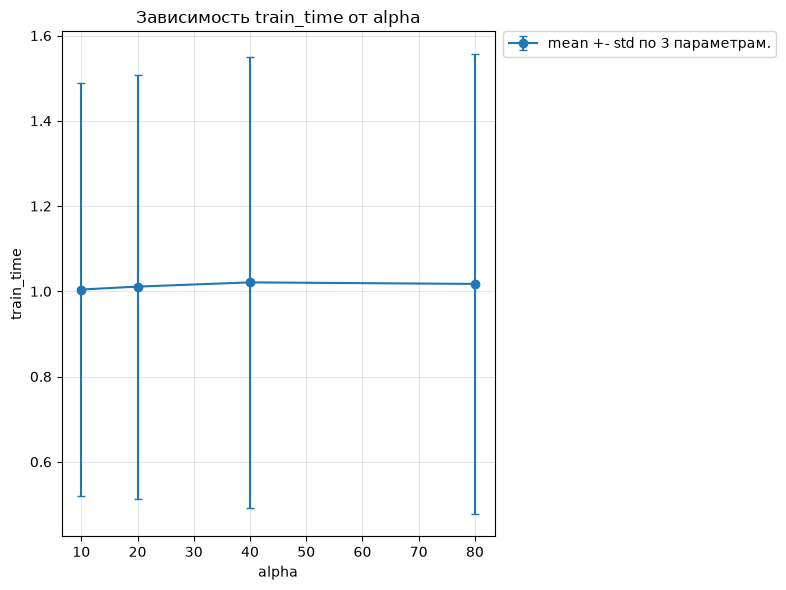

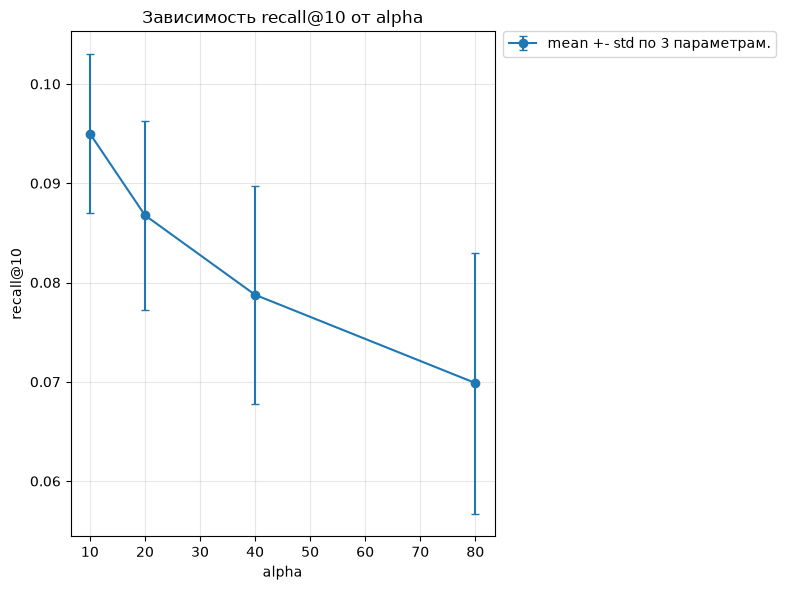

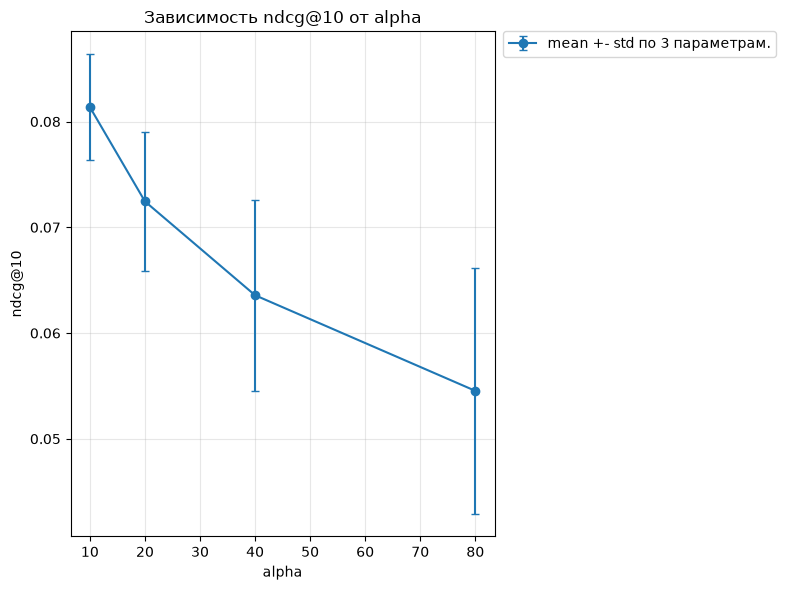

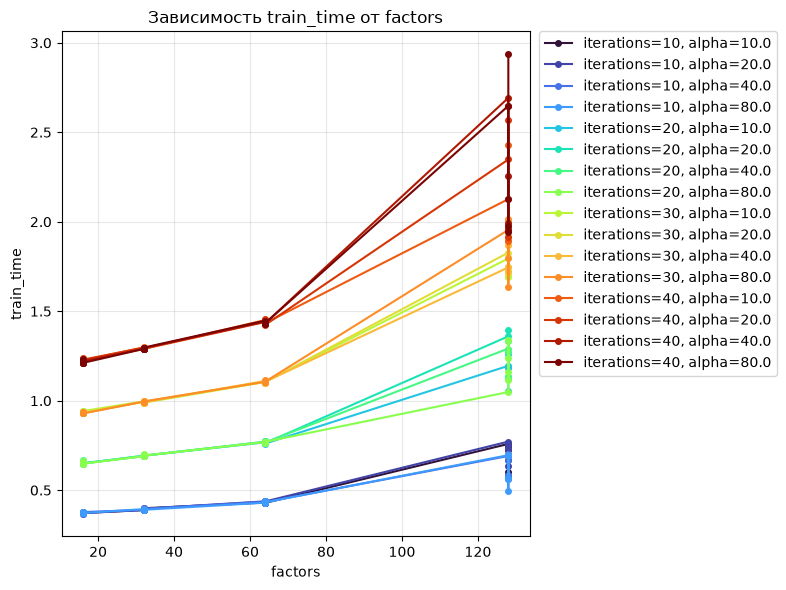

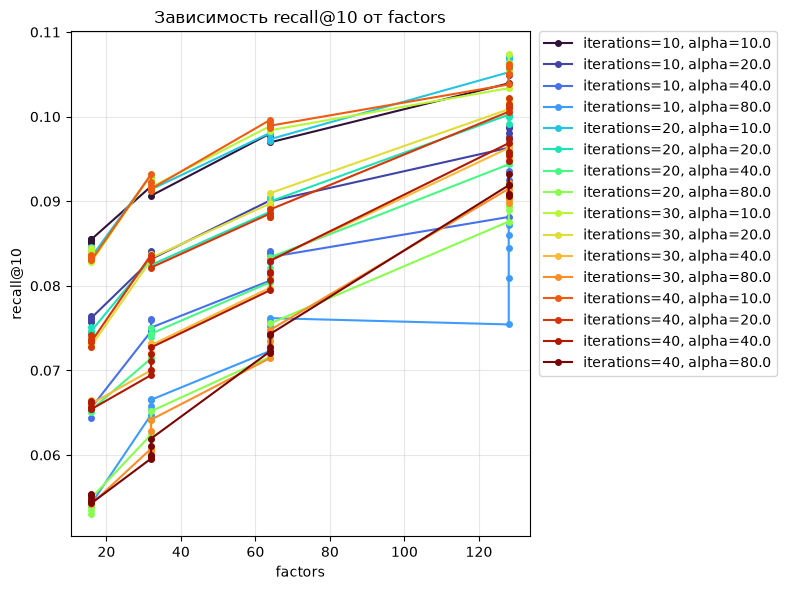

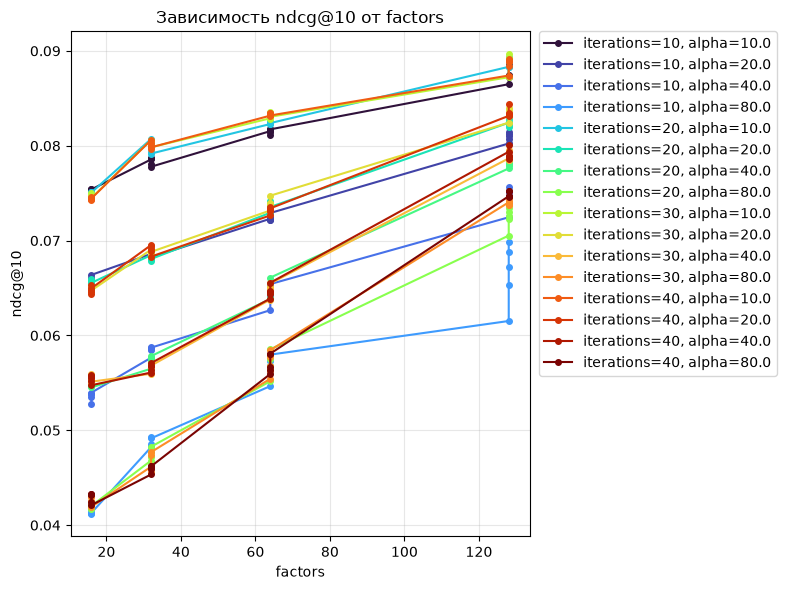

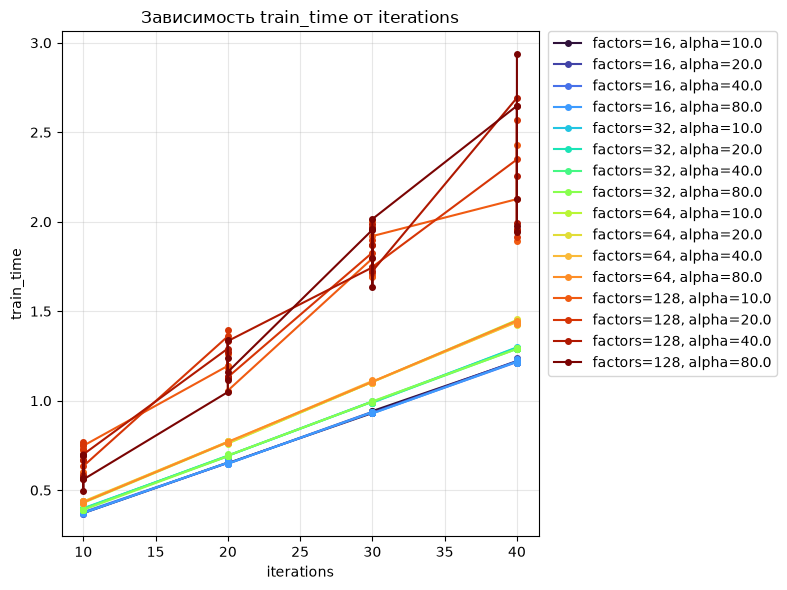

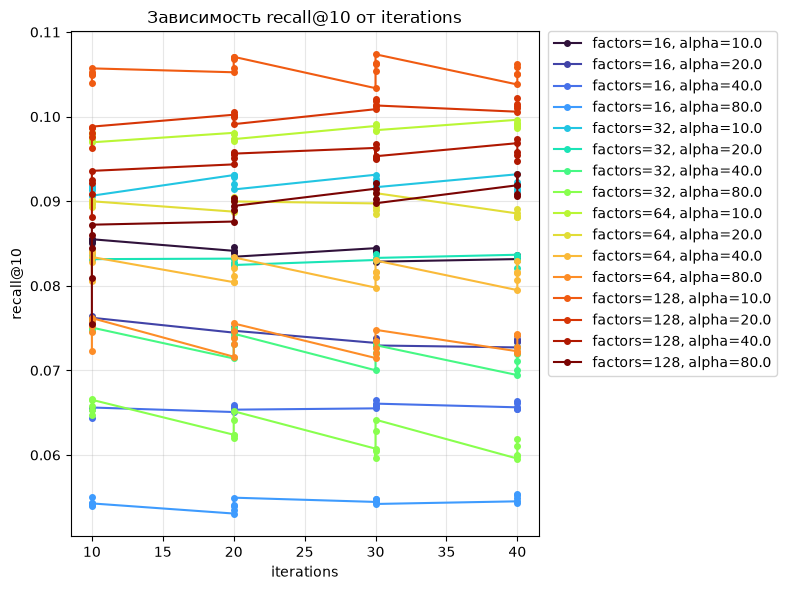

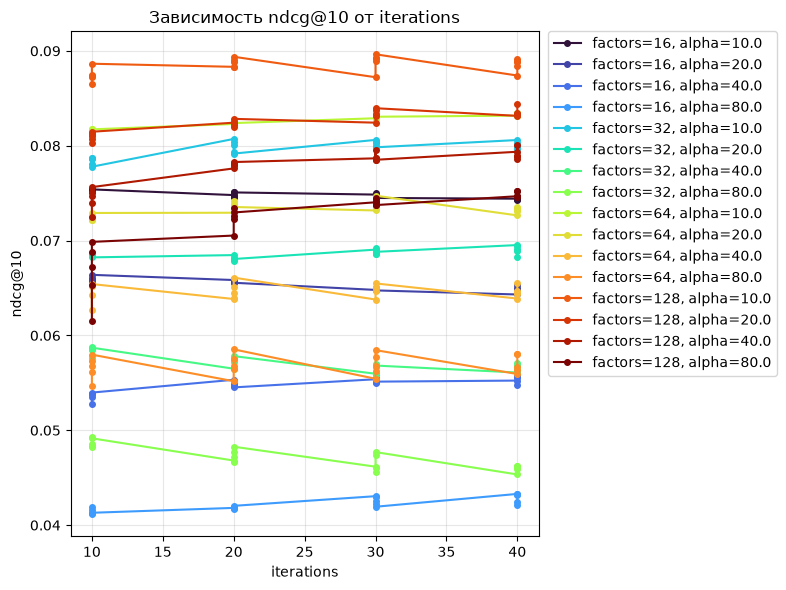

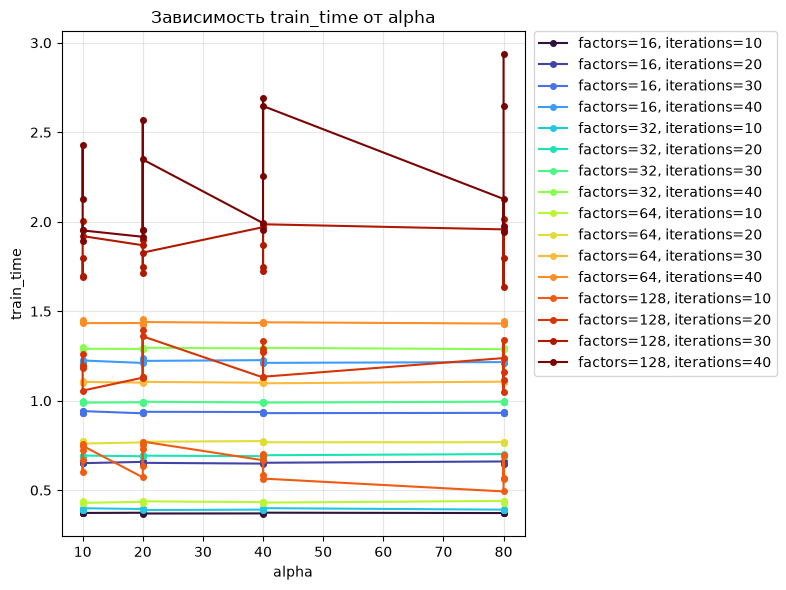

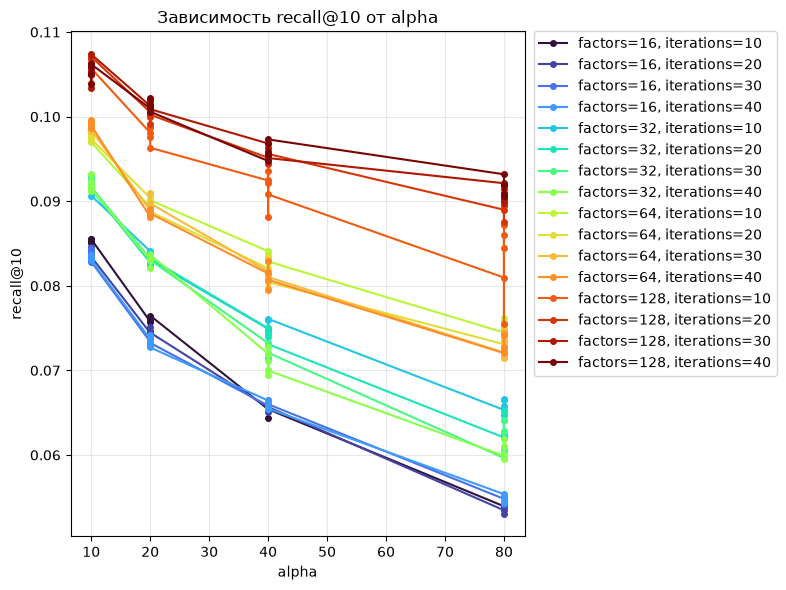

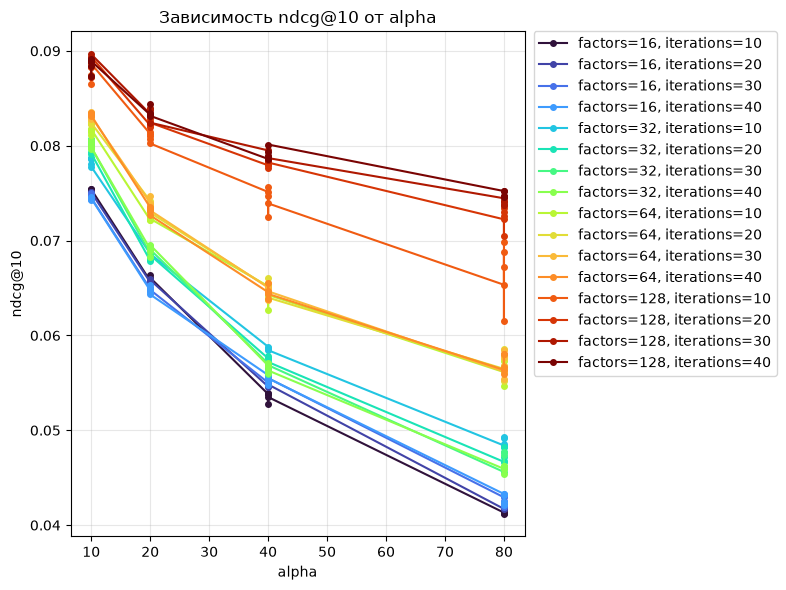

In [20]:
with open(IMPLICIT_ALS_PARAMS_SEARCH_PATH, "rb") as f:
    df_ImplicitALS = pickle.load(f)

show_graph(
    results_df=df_ImplicitALS,
    params=["factors", "iterations", "regularization", "alpha"],
    metrics=["train_time", "recall@10", "ndcg@10"],
    save_dir="graphs/implicitALS",
    max_lines=10
)

show_graph(
    results_df=df_ImplicitALS,
    params=["factors", "iterations", "alpha"],
    metrics=["train_time", "recall@10", "ndcg@10"],
    save_dir="graphs/implicitALS",
    max_lines=None
)

In [24]:
with open(IMPLICIT_ALS_PARAMS_SEARCH_PATH, "rb") as f:
    df_ImplicitALS = pickle.load(f)

df_ImplicitALS.to_csv("../data/processed/df_ImplicitALS.csv", index=False)

df_ImplicitALS

,factors,iterations,regularization,alpha,train_time,pred_time,train_mem_delta,train_mem_peak,train_mem_start,pred_mem_delta,pred_mem_peak,pred_mem_start,recall@10,ndcg@10
0,16,10,0.01,10.0,0.370424,0.988255,56.733073,1352.710938,1295.977865,0.566406,1304.608073,1304.041667,0.085261,0.075456
1,16,10,0.01,20.0,0.369757,0.994180,57.989583,1353.649740,1295.660156,0.037760,1304.941406,1304.903646,0.076474,0.066077
2,16,10,0.01,40.0,0.369604,0.998594,58.141927,1354.152344,1296.010417,0.031250,1305.463542,1305.432292,0.064317,0.052813
3,16,10,0.01,80.0,0.370038,0.985560,58.588542,1353.798177,1295.209635,0.032552,1305.096354,1305.063802,0.054141,0.041224
4,16,10,0.05,10.0,0.375379,1.028315,58.666667,1353.880208,1295.213542,0.031250,1305.175781,1305.144531,0.085069,0.075089
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
315,128,40,0.20,80.0,1.974071,2.378164,71.393229,1369.722656,1298.329427,0.029948,1320.015625,1319.985677,0.090822,0.074671
316,128,40,0.50,10.0,1.951583,2.463083,70.639323,1368.984375,1298.345052,0.029948,1320.005208,1319.975260,0.106190,0.088914
317,128,40,0.50,20.0,1.952407,2.513185,75.329427,1373.654948,1298.325521,0.029948,1320.031250,1320.001302,0.102226,0.084380
318,128,40,0.50,40.0,2.257004,2.290974,72.562500,1370.819010,1298.256510,0.029948,1320.011719,1319.981771,0.095475,0.078953


Оптимальный выбор параметров на валидационной выборке: `factors=128`, `iterations=30`, `regularization=0.5`, `alpha=10.0`.

На графике зависимости `NDCG@10` от `factors` видно, что 128 факторов дают прирост качества по сравнению с 16, 32 и 64 - модель лучше улавливает скрытые связи между пользователями и фильмами за счет более большого представления скрытых векторов. Для задач ранжирования (рекомендаций) прирост `NDCG` наиболее важен для бизнеса, поэтому имеет смысл брать максимальное значение из рассмотренных.

Для 128 факторов график `NDCG@10` от `iterations` показывает, что модель демонстрирует лучшие метрики при значении `iterations=30`. Увеличение числа итераций позволяет ALS лучше сойтись к оптимальному разложению, а при 30 итерациях достигается оптимум качества на валидационной выборке без лишних затрат времени на обучение.

Влияние `regularization` на `NDCG@10` выражено слабо. Слишком малый коэффициент регуляризации повышает риск переобучения, поэтому оптимальным выбрано значение `0.5`, которое снижает риск переобучения на разреженных данных без потери качества.

По графику `NDCG@10` от `alpha` видно, что качество монотонно убывает с ростом `alpha` и достигает максимума в районе `alpha=10.0`. Поскольку модель обучается только на положительных взаимодействиях (`rating >= 3.5`), дальнейшее увеличение `alpha` снижает метрику: слишком большой вес уверенности начинает усиливать смещение в сторону популярных оценок, тогда как значение 10.0 обеспечивает оптимальный баланс.

In [26]:
def model_factory():
    return ImplicitALS(factors=128, iterations=30, regularization=0.5, alpha=10.0)

train_val = pd.concat([train, val], ignore_index=True)

results = run_benchmark(model_factory, train_val, test, n_runs=N_RUNS)

print_summary(results)

[timer] Обучение implicit ALS(factors=128, iterations=30, regularization=0.5, alpha=10.0): 1.847 сек.
[memory_usage] Обучение implicit ALS(factors=128, iterations=30, regularization=0.5, alpha=10.0): 78.430 MB
[timer] Выдача рекомендаций implicit ALS(factors=128, iterations=30, regularization=0.5, alpha=10.0): 1.663 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=128, iterations=30, regularization=0.5, alpha=10.0): 0.020 MB
[timer] Обучение implicit ALS(factors=128, iterations=30, regularization=0.5, alpha=10.0): 1.999 сек.
[memory_usage] Обучение implicit ALS(factors=128, iterations=30, regularization=0.5, alpha=10.0): 80.965 MB
[timer] Выдача рекомендаций implicit ALS(factors=128, iterations=30, regularization=0.5, alpha=10.0): 1.710 сек.
[memory_usage] Выдача рекомендаций implicit ALS(factors=128, iterations=30, regularization=0.5, alpha=10.0): 0.020 MB
[timer] Обучение implicit ALS(factors=128, iterations=30, regularization=0.5, alpha=10.0): 2.147 сек.
[memory_usage] О

| Алгоритм | Параметры | Train time, сек | Predict time, сек | Прирост RSS при обучении, МБ | Пиковый RSS при обучении, МБ | Прирост RSS при предсказании, МБ | Пиковый RSS при предсказании, МБ | Recall@10 | NDCG@10 |
|----------|-----------|-----------------|-------------------|------------------------------|------------------------------|----------------------------------|----------------------------------|-----------|---------|
| UserBasedCF | top_k=5 | 2.648 | 2.903 | 1261.25 | 2518.90 | 551.88 | 2519.11 | 0.0407 | 0.0438 |
| ImplicitALS | factors=128, iterations=30, regularization=0.5, alpha=10.0 | 1.998 | 1.669 | 79.56 | 1388.42 | 0.02 | 1331.70 | 0.0878 | 0.1120 |

На отложенной тестовой выборке `ImplicitALS` превосходит `UserBasedCF` по всем измеряемым метрикам: показывает более высокий `NDCG@10` (0.1120 против 0.0438, в 2.56 раза выше) и более высокий `Recall@10` (0.0878 против 0.0407, в 2.16 раза выше) за счет исключения уже оцененных фильмов при выдаче рекомендаций и обучения только на положительных оценках.

При этом `ImplicitALS` выигрывает по стоимости эксплуатации: обучение быстрее (1.998 с против 2.648 с), предсказание быстрее почти в 2 раза, а прирост RSS при обучении меньше почти в 16 раз, при предсказании тоже намного меньше. Поэтому `ALS` более предпочтительный при масштабировании на 10M/32M.